In [1]:
from scipy.io import arff
import pandas as pd

data = arff.loadarff("../data/raw/nasa93.arff")
df = pd.DataFrame(data[0])

df.head()

,recordnumber,projectname,cat2,forg,center,year,mode,rely,data,cplx,...,acap,aexp,pcap,vexp,lexp,modp,tool,sced,equivphyskloc,act_effort
0,1.0,b'de',b'avionicsmonitoring',b'g',b'2',1979.0,b'semidetached',b'h',b'l',b'h',...,b'n',b'n',b'n',b'n',b'h',b'h',b'n',b'l',25.9,117.6
1,2.0,b'de',b'avionicsmonitoring',b'g',b'2',1979.0,b'semidetached',b'h',b'l',b'h',...,b'n',b'n',b'n',b'n',b'h',b'h',b'n',b'l',24.6,117.6
2,3.0,b'de',b'avionicsmonitoring',b'g',b'2',1979.0,b'semidetached',b'h',b'l',b'h',...,b'n',b'n',b'n',b'n',b'h',b'h',b'n',b'l',7.7,31.2
3,4.0,b'de',b'avionicsmonitoring',b'g',b'2',1979.0,b'semidetached',b'h',b'l',b'h',...,b'n',b'n',b'n',b'n',b'h',b'h',b'n',b'l',8.2,36.0
4,5.0,b'de',b'avionicsmonitoring',b'g',b'2',1979.0,b'semidetached',b'h',b'l',b'h',...,b'n',b'n',b'n',b'n',b'h',b'h',b'n',b'l',9.7,25.2


In [2]:
df.head()

,recordnumber,projectname,cat2,forg,center,year,mode,rely,data,cplx,...,acap,aexp,pcap,vexp,lexp,modp,tool,sced,equivphyskloc,act_effort
0,1.0,b'de',b'avionicsmonitoring',b'g',b'2',1979.0,b'semidetached',b'h',b'l',b'h',...,b'n',b'n',b'n',b'n',b'h',b'h',b'n',b'l',25.9,117.6
1,2.0,b'de',b'avionicsmonitoring',b'g',b'2',1979.0,b'semidetached',b'h',b'l',b'h',...,b'n',b'n',b'n',b'n',b'h',b'h',b'n',b'l',24.6,117.6
2,3.0,b'de',b'avionicsmonitoring',b'g',b'2',1979.0,b'semidetached',b'h',b'l',b'h',...,b'n',b'n',b'n',b'n',b'h',b'h',b'n',b'l',7.7,31.2
3,4.0,b'de',b'avionicsmonitoring',b'g',b'2',1979.0,b'semidetached',b'h',b'l',b'h',...,b'n',b'n',b'n',b'n',b'h',b'h',b'n',b'l',8.2,36.0
4,5.0,b'de',b'avionicsmonitoring',b'g',b'2',1979.0,b'semidetached',b'h',b'l',b'h',...,b'n',b'n',b'n',b'n',b'h',b'h',b'n',b'l',9.7,25.2


In [3]:
for col in df.columns:
    if df[col].dtype == object:
        df[col] = df[col].apply(lambda x: x.decode("utf-8") if isinstance(x, bytes) else x)
        

In [4]:
df.head()

,recordnumber,projectname,cat2,forg,center,year,mode,rely,data,cplx,...,acap,aexp,pcap,vexp,lexp,modp,tool,sced,equivphyskloc,act_effort
0,1.0,de,avionicsmonitoring,g,2,1979.0,semidetached,h,l,h,...,n,n,n,n,h,h,n,l,25.9,117.6
1,2.0,de,avionicsmonitoring,g,2,1979.0,semidetached,h,l,h,...,n,n,n,n,h,h,n,l,24.6,117.6
2,3.0,de,avionicsmonitoring,g,2,1979.0,semidetached,h,l,h,...,n,n,n,n,h,h,n,l,7.7,31.2
3,4.0,de,avionicsmonitoring,g,2,1979.0,semidetached,h,l,h,...,n,n,n,n,h,h,n,l,8.2,36.0
4,5.0,de,avionicsmonitoring,g,2,1979.0,semidetached,h,l,h,...,n,n,n,n,h,h,n,l,9.7,25.2


In [5]:
# Dataset validation and data-quality summary

print("NASA93 dataset overview")
print("=" * 40)

print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nColumn names and data types:")
display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Unique Values": df.nunique(dropna=True).values
}))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values by column:")
missing = df.isna().sum()
print(missing[missing > 0] if missing.any() else "No missing values found.")

print("\nNumeric summary:")
display(df.describe().T)

NASA93 dataset overview
Rows: 93
Columns: 24

Column names and data types:


,Column,Data Type,Missing Values,Unique Values
0,recordnumber,float64,0,93
1,projectname,str,0,8
2,cat2,str,0,14
3,forg,str,0,2
4,center,str,0,5
5,year,float64,0,14
6,mode,str,0,3
7,rely,str,0,4
8,data,str,0,4
9,cplx,str,0,5



Duplicate rows: 0

Missing values by column:
No missing values found.

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
recordnumber,93.0,47.752688,28.229901,1.0,24.0,47.0,70.0,101.0
year,93.0,1980.827957,3.335004,1971.0,1979.0,1980.0,1983.0,1987.0
equivphyskloc,93.0,94.022043,133.597947,0.9,15.4,47.5,111.0,980.0
act_effort,93.0,624.411828,1135.928065,8.4,70.0,252.0,600.0,8211.0


No missing values to plot.


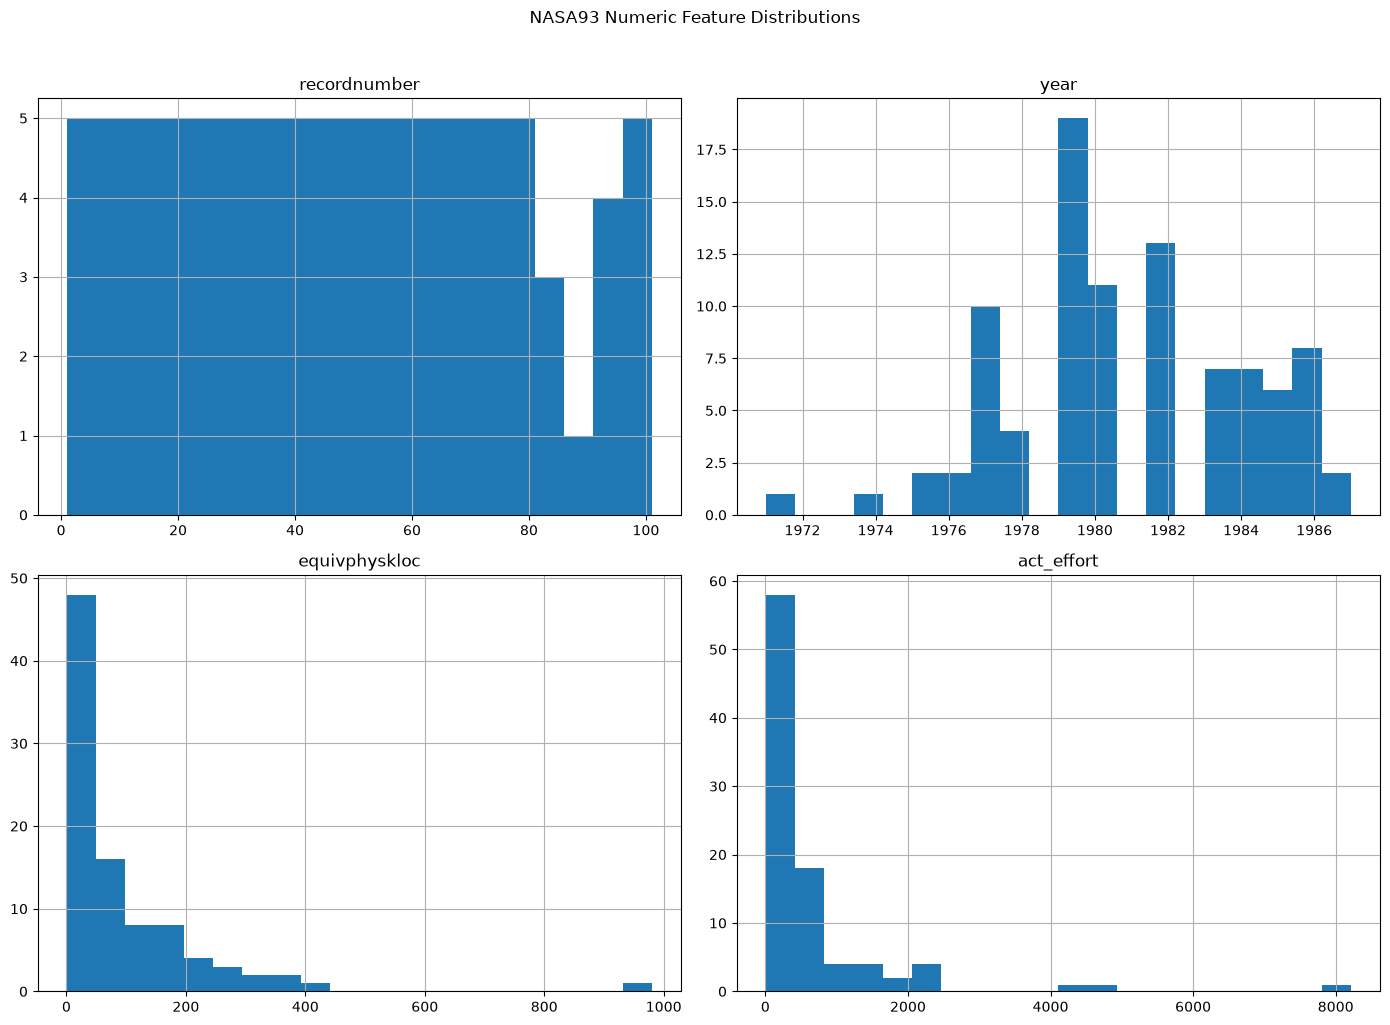

In [6]:
# Visualize missing values and numeric feature distributions

import matplotlib.pyplot as plt

# Missing values by column
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    missing.plot(kind="bar", figsize=(10, 4))
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Value Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values to plot.")

# Distributions of numeric columns
numeric_df = df.select_dtypes(include="number")

if not numeric_df.empty:
    numeric_df.hist(figsize=(14, 10), bins=20)
    plt.suptitle("NASA93 Numeric Feature Distributions", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns available for distribution plots.")